# Makale Yeniden Üretimi: *Fairwashing: the risk of rationalization* (Aïvodji ve ark., 2019)

**Makale:** U. Aïvodji, H. Arai, O. Fortineau, S. Gambs, S. Hara, A. Tapp. *Fairwashing: the risk of rationalization.* ICML 2019. [arXiv:1901.09749](https://arxiv.org/abs/1901.09749) · Orijinal kod: [aivodji/LaundryML](https://github.com/aivodji/LaundryML)
**Tespit makalesi (uzantı):** Shamsabadi ve ark. *Washing the Unwashable: On the (Im)possibility of Fairwashing Detection.* NeurIPS 2022 · Kod: [cleverhans-lab/FRAUD-Detect](https://github.com/cleverhans-lab/FRAUD-Detect)

**Konu 25 (Global Surrogate) · Seçenek 1: Zafiyet/Manipülasyon.** Makalenin iddiası: adaletsiz bir kara kutu, kara kutuya yüksek sadakatli ama çok daha adil görünen bir surrogate ile "aklanabilir". Surrogate'ın sadakati yüksek olduğu için denetçi kara kutunun adil olduğuna inanır.

**Bu defterde yapılanlar**

| Bölüm | Ne yapılıyor | Makaledeki karşılığı |
|---|---|---|
| 1 | Saldırının mantığı: LaundryML amaç fonksiyonu ve FRAUD-Detect | Bölüm 3, Algoritma 1 (NeurIPS 2022) |
| 2 | **Orijinal Adult verisinde** deneyin yeniden üretimi (5 bölme) | Tablo 1, Şekil 1, seçim kuralı, Şekil 3 |
| 3 | **Kendi verimde** (Kaggle German Credit) aynı saldırı ve canlı demo | Yeni katkı |
| 4 | Duyarlılık: suing group boyutu ve model karmaşıklığı | Tablo 1 test sütunu (genelleme) |
| 5 | **Uzantı:** FRAUD-Detect bu aklamayı yakalar mı? | Yeni katkı (NeurIPS 2022 ile birleştirme) |
| 6 | Sonuç ve tartışma (sayılar çıktılardan otomatik yazılır) | |

**Kapsam notu (makaleden farklarım).**
1. Makale CORELS ile **kural listesi** numaralandırır (LaundryML). Ben sığ **karar ağaçlarından bir aday havuzu** kuruyor ve aynı amaç fonksiyonuyla seçiyorum. Bu yüzden sayılar makaledekiyle birebir aynı çıkmaz, yeniden üretilen şey bulgunun niteliğidir.
2. Makale veri bölme oranlarını vermiyor. Adult için %50 / %25 / %25, German için %40 / %30 / %30 kullandım.
3. Makalenin FairML denetimi yerine **permütasyon önemi** kullandım.
4. FRAUD-Detect algoritmasını makaledeki gibi uyguladım. İki farkım var: eşik τ'yu kendim kalibre ettim (dürüst surrogate'ların bootstrap dağılımı) ve küçük alt gruplarda oranlar oynak olduğu için alt grup oranlarına Laplace düzeltmesi ekledim.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

SEED = 0
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
COL_BB, COL_HON, COL_FW = "#444444", "#1f77b4", "#d62728"   # kara kutu: gri, dürüst: mavi, aklanmış: kırmızı

## Yardımcı kod: veri, aday havuzu, LaundryML amaç fonksiyonu, FRAUD-Detect

Aşağıdaki hücre bu defterin tüm mantığını tek yerde toplar. Makaledeki kurguyu izler: kara kutu **suing group'u etiketler**, surrogate bu etiketlerle eğitilir, sadakat ve adaletsizlik **suing group** üzerinde ölçülür, test kümesi genellemeyi görmek içindir.

In [2]:
# ---------------------------------------------------------------------------
# Ölçütler
# ---------------------------------------------------------------------------
def unfair(pred, s):
    """Demografik parite farkı: |P(ŷ=1 | s=1) − P(ŷ=1 | s=0)|  (makaledeki adaletsizlik)."""
    return float(abs(pred[s == 1].mean() - pred[s == 0].mean()))


def fid(a, b):
    """Sadakat: iki modelin aynı tahmini verdiği oran."""
    return float((a == b).mean())


# ---------------------------------------------------------------------------
# Veri
# ---------------------------------------------------------------------------
def load_adult():
    """Makalenin verisi: UCI Adult, gelir > 50K, hassas özellik cinsiyet."""
    ad = fetch_openml("adult", version=2, as_frame=True).frame.dropna().copy()
    y = (ad["class"] == ">50K").astype(int).values
    X = pd.get_dummies(ad.drop(columns=["class", "fnlwgt"])).astype(float)
    X.columns = [str(c) for c in X.columns]
    return X, y, "sex_Male", "sex_"




def veri_hazirla(ad="veri.csv"):
    """veri.csv defterle aynı klasörde olmalı. Yoksa Colab'da yükleme penceresi açılır."""
    if os.path.exists(ad):
        return
    try:
        from google.colab import files          # yalnızca Colab'da vardır
        print(f"{ad} bulunamadı. Açılan pencereden veri.csv dosyasını seçin.")
        files.upload()
    except ImportError:
        pass
    if not os.path.exists(ad):
        raise FileNotFoundError(f"{ad} bulunamadı. Dosyayı bu defterle aynı klasöre koyup hücreyi yeniden çalıştırın.")


def load_german():
    """Kendi verim: Kaggle German Credit (1000 başvuru). Hedef: Risk = good. Hassas özellik: Sex (erkek = 1)."""
    veri_hazirla("veri.csv")
    raw = pd.read_csv("veri.csv", keep_default_na=False)
    raw = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")])
    y = (raw["Risk"] == "good").astype(int).values
    raw["Sex"] = (raw["Sex"] == "male").astype(int)
    X = pd.get_dummies(raw.drop(columns=["Risk"]),
                       columns=["Housing", "Saving accounts", "Checking account", "Purpose"], dtype=int).astype(float)
    return X, y, "Sex", "Sex"


def split3(X, y, seed, frac_tr):
    """Eğitim / suing group / test. Makale oranları vermiyor; eğitim payını frac_tr ile veriyorum, kalanı yarıya bölüyorum."""
    X_tr, X_rest, y_tr, y_rest = train_test_split(X, y, train_size=frac_tr, stratify=y, random_state=seed)
    X_su, X_te, y_su, y_te = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=seed)
    return X_tr, X_su, X_te, y_tr, y_su, y_te


# ---------------------------------------------------------------------------
# Aday havuzu (LaundryML'in kural listesi numaralandırmasının yerine)
# ---------------------------------------------------------------------------
def build_pool(X_su, bb_su, s_su, feat_all, feat_ns, seed, msl):
    """Sığ karar ağaçları: derinlik x hassas sütun kullanımı x adalet cezası (örnek ağırlığı).
    lw = 0 ve hassas sütun açık olan modeller 'dürüst' surrogate'lardır."""
    hi = 1 if bb_su[s_su == 1].mean() >= bb_su[s_su == 0].mean() else 0   # kara kutunun kayırdığı grup
    cell = ((s_su == hi) & (bb_su == 1)) | ((s_su != hi) & (bb_su == 0))  # adaletsizliği besleyen hücreler
    rows = []
    for use_sens in [True, False]:
        feats = feat_all if use_sens else feat_ns
        for lw in [0, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95]:
            w = np.ones(len(X_su))
            w[cell] = 1 - lw
            for depth in [2, 3, 4, 5, 6, 8]:
                t = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=msl, random_state=seed)
                t.fit(X_su[feats], bb_su, sample_weight=w)
                p = t.predict(X_su[feats])
                rows.append(dict(model=t, feats=feats, use_sens=use_sens, lw=lw, depth=depth,
                                 K=int(t.get_n_leaves()), fid=fid(p, bb_su), misc=1 - fid(p, bb_su),
                                 unfair=unfair(p, s_su), pred=p))
    return pd.DataFrame(rows), hi


BETAS = [0.0, 0.1, 0.2, 0.5, 0.7, 0.9]     # makaledeki β ızgarası
LAMS = [0.005, 0.01]                        # makaledeki λ ızgarası


def laundry_grid(pool):
    """Makalenin amaç fonksiyonu:  obj = (1−β)·misc + β·unfairness + λ·K   (K: yaprak sayısı)."""
    rows = []
    for lam in LAMS:
        for beta in BETAS:
            obj = (1 - beta) * pool.misc + beta * pool.unfair + lam * pool.K
            i = int(obj.idxmin())
            rows.append(dict(beta=beta, lam=lam, idx=i, fid=pool.fid[i], unfair=pool.unfair[i], K=pool.K[i]))
    return pd.DataFrame(rows)


def select_best(pool, bb_unf):
    """Makalenin seçim kuralı: kara kutudan en az 2 kat daha az adaletsiz olanlar arasından en sadakatli olan."""
    ok = pool[pool.unfair <= bb_unf / 2]
    if len(ok):
        return int(ok.fid.idxmax()), True
    return int(pool.unfair.idxmin()), False


# ---------------------------------------------------------------------------
# FRAUD-Detect (Shamsabadi ve ark., NeurIPS 2022, Algoritma 1)
# ---------------------------------------------------------------------------
def c_kl(pred_I, pred_B, s, eps=1e-6):
    """Her alt grup a için, kara kutu B'nin tahminini referans alarak surrogate I'nın [TPR, FPR, TNR, FNR]
    vektörü; C_KL = KL(C_0 || C_1). Vektörleri 2'ye bölüp dağılıma çeviriyorum.
    Makaleden fark: küçük alt gruplarda oranlar çok oynak olduğu için Laplace düzeltmesi (+0,5 / +1) kullanıyorum."""
    C = []
    for a in [0, 1]:
        m = s == a
        b1, b0 = m & (pred_B == 1), m & (pred_B == 0)
        tpr = (pred_I[b1].sum() + 0.5) / (b1.sum() + 1)
        fpr = (pred_I[b0].sum() + 0.5) / (b0.sum() + 1)
        v = np.array([tpr, fpr, 1 - fpr, 1 - tpr]) / 2 + eps
        C.append(v / v.sum())
    return float(np.sum(C[0] * np.log(C[0] / C[1])))


def calibrate_tau(X_su, bb_su, s_su, feat_all, seed, msl, n_boot=15):
    """Eşik τ: dürüst surrogate'ların bootstrap dağılımının 95. yüzdeliği (kendi kalibrasyonum)."""
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        idx = rng.choice(len(X_su), len(X_su), replace=True)
        for depth in [3, 4, 5]:
            t = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=msl, random_state=seed)
            t.fit(X_su.iloc[idx][feat_all], bb_su[idx])
            vals.append(c_kl(t.predict(X_su[feat_all]), bb_su, s_su))
    return float(np.percentile(vals, 95)), vals


# ---------------------------------------------------------------------------
# Tüm hat: kara kutu -> aday havuzu -> seçim -> tespit
# ---------------------------------------------------------------------------
def run_pipeline(data, seed, frac_tr, msl, n_boot=15, keep=False):
    X, y, SENS, PRE = data
    X_tr, X_su, X_te, y_tr, y_su, y_te = split3(X, y, seed, frac_tr)
    bb = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=-1).fit(X_tr, y_tr)
    bb_su, bb_te = bb.predict(X_su), bb.predict(X_te)
    s_su, s_te = X_su[SENS].values, X_te[SENS].values
    feat_all = list(X.columns)
    feat_ns = [c for c in feat_all if not c.startswith(PRE)]

    pool, hi = build_pool(X_su, bb_su, s_su, feat_all, feat_ns, seed, msl)
    grid = laundry_grid(pool)
    bb_unf_su, bb_unf_te = unfair(bb_su, s_su), unfair(bb_te, s_te)
    bi, ok = select_best(pool, bb_unf_su)
    best = pool.loc[bi]
    p_te = best.model.predict(X_te[best.feats])
    pool["ckl"] = [c_kl(p, bb_su, s_su) for p in pool.pred]
    tau, boot = calibrate_tau(X_su, bb_su, s_su, feat_all, seed, msl, n_boot)

    taban = float(max(bb_su.mean(), 1 - bb_su.mean()))   # kara kutunun çoğunluk sınıfını sabit tahmin eden surrogate'ın sadakati
    res = dict(seed=seed, bb_acc_te=float((bb_te == y_te).mean()), bb_unf_su=bb_unf_su, bb_unf_te=bb_unf_te,
               taban_fid=taban, fid_su=best.fid, unf_su=best.unfair, fid_te=fid(p_te, bb_te), unf_te=unfair(p_te, s_te),
               K=best.K, kural_saglandi=ok, dürüst_model=bool(best.lw == 0 and best.use_sens),
               ckl=float(pool.ckl[bi]), tau=tau, detected=bool(pool.ckl[bi] > tau))
    if keep:
        res["ctx"] = dict(X=X, SENS=SENS, PRE=PRE, msl=msl, X_su=X_su, X_te=X_te, bb=bb, bb_su=bb_su, bb_te=bb_te,
                          s_su=s_su, s_te=s_te, feat_all=feat_all, feat_ns=feat_ns, pool=pool, hi=hi, grid=grid,
                          best_i=bi, bb_unf_su=bb_unf_su, bb_unf_te=bb_unf_te, tau=tau, boot=boot)
    return res


def summarize(runs):
    return pd.DataFrame([{k: v for k, v in r.items() if k != "ctx"} for r in runs]).set_index("seed")


# ---------------------------------------------------------------------------
# Şekil 1 karşılığı, denetim, kural yolu, kontrollü aklama
# ---------------------------------------------------------------------------
def plot_fig1(ctx, title):
    pool, grid = ctx["pool"], ctx["grid"]
    fig, ax = plt.subplots(figsize=(6.4, 4.4))
    ax.scatter(pool.unfair, pool.fid, s=16, color="#c7c7c7", label="tüm adaylar")
    for lam, mk in [(0.005, "o"), (0.01, "s")]:
        g = grid[grid.lam == lam]
        sc = ax.scatter(g.unfair, g.fid, c=g.beta, cmap="viridis", marker=mk, s=80, edgecolor="k",
                        label=f"λ={lam}", vmin=0, vmax=0.9)
    plt.colorbar(sc, ax=ax, label="β")
    ax.axvline(ctx["bb_unf_su"], ls="--", color=COL_FW, label="kara kutu adaletsizliği")
    b = pool.loc[ctx["best_i"]]
    ax.scatter([b.unfair], [b.fid], marker="*", s=260, color=COL_FW, edgecolor="k", zorder=5, label="seçilen model")
    ax.set(xlabel="adaletsizlik (suing group)", ylabel="sadakat (suing group)", title=title)
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig


def rank_of_sensitive(imp, prefix):
    return {c: 1 + int((imp > imp[c]).sum()) for c in imp.index if c.startswith(prefix)}


def audit(ctx, n_rows=2000, seed=0):
    """FairML denetiminin karşılığı: hassas özelliğin önem sırası (1 = en önemli)."""
    X_su, bb, bb_su, pool = ctx["X_su"], ctx["bb"], ctx["bb_su"], ctx["pool"]
    sub = np.random.default_rng(seed).choice(len(X_su), min(n_rows, len(X_su)), replace=False)
    pi = permutation_importance(bb, X_su.iloc[sub], bb_su[sub], n_repeats=2, random_state=seed, n_jobs=-1)
    imp_bb = pd.Series(pi.importances_mean, index=X_su.columns)

    def tree_imp(row):
        s = pd.Series(0.0, index=X_su.columns)
        s[row.feats] = row.model.feature_importances_
        return s
    hon = pool[(pool.lw == 0) & pool.use_sens].sort_values("depth").iloc[-1]
    return pd.DataFrame({
        "kara kutu": rank_of_sensitive(imp_bb, ctx["PRE"]),
        "dürüst surrogate": rank_of_sensitive(tree_imp(hon), ctx["PRE"]),
        "aklanmış surrogate": rank_of_sensitive(tree_imp(pool.loc[ctx["best_i"]]), ctx["PRE"]),
    })


def rule_path(tree, feats, x):
    """Bir müşterinin ağaçta izlediği kural yolu."""
    xv = x[feats].values.astype(float)
    t = tree.tree_
    node, out = 0, []
    while t.children_left[node] != -1:
        f, thr = t.feature[node], t.threshold[node]
        left = xv[f] <= thr
        out.append(f"{feats[f]} {'<=' if left else '>'} {thr:.2f}   (müşterinin değeri: {xv[f]:.2f})")
        node = t.children_left[node] if left else t.children_right[node]
    return out


def controlled(ctx, qs, seed=0):
    """Kontrollü 'ideal' aklama: kara kutu kararlarını adaletsizliği besleyen hücrelerde olasılık q ile çevir.
    Karşılaştırma: gruptan bağımsız rastgele gürültü. FRAUD-Detect'in doğru çalıştığını ayrı olarak sınar."""
    rng = np.random.default_rng(seed)
    bb_su, s_su, hi = ctx["bb_su"], ctx["s_su"], ctx["hi"]
    rows = []
    for q in qs:
        I = bb_su.copy()
        I[(s_su == hi) & (bb_su == 1) & (rng.random(len(I)) < q)] = 0
        I[(s_su != hi) & (bb_su == 0) & (rng.random(len(I)) < q)] = 1
        J = bb_su.copy()
        fl = rng.random(len(J)) < q * 0.3
        J[fl] = 1 - J[fl]
        rows.append(dict(q=q, sadakat=fid(I, bb_su), eps_aklama=ctx["bb_unf_su"] - unfair(I, s_su),
                         CKL_aklama=c_kl(I, bb_su, s_su), eps_gürültü=ctx["bb_unf_su"] - unfair(J, s_su),
                         CKL_gürültü=c_kl(J, bb_su, s_su)))
    return pd.DataFrame(rows)


def fairwash_subset(ctx, n, seed):
    """Suing group'u n örneğe küçült, aklamayı o örneklemde yap, sonra TEST kümesinde ölç."""
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(ctx["X_su"]), n, replace=False)
    Xs, bs, ss_ = ctx["X_su"].iloc[idx], ctx["bb_su"][idx], ctx["s_su"][idx]
    pool, _ = build_pool(Xs, bs, ss_, ctx["feat_all"], ctx["feat_ns"], seed, ctx["msl"])
    bu = unfair(bs, ss_)
    bi, ok = select_best(pool, bu)
    b = pool.loc[bi]
    p_te = b.model.predict(ctx["X_te"][b.feats])
    return dict(n=n, bb_unf_su=bu, unf_su=b.unfair, fid_su=b.fid,
                unf_te=unfair(p_te, ctx["s_te"]), fid_te=fid(p_te, ctx["bb_te"]))

## 1. Saldırının mantığı (özet)

**LaundryML amaç fonksiyonu.** Makale, kara kutu $b$'yi taklit eden ve aynı zamanda adil görünen bir açıklama $g$ arar:

$$
\min_g \;\; (1-\beta)\cdot \text{misc}(g,b) \;+\; \beta\cdot \text{unfairness}(g) \;+\; \lambda\cdot K(g)
$$

* $\text{misc}$: suing group'ta $g$ ile $b$'nin uyuşmadığı oran (1 − sadakat)
* $\text{unfairness}$: demografik parite farkı, $|P(g=1\mid s=1)-P(g=1\mid s=0)|$
* $K$: model uzunluğu (burada yaprak sayısı), $\beta$ adalet ağırlığı, $\lambda$ sadelik cezası

**Seçim kuralı.** Kara kutudan **en az 2 kat daha az adaletsiz** olan modeller arasından **en yüksek sadakatli** olan seçilir.

**FRAUD-Detect (tespit).** Suing set üzerinde surrogate $I$ ve kara kutu $B$ sorgulanır. Her alt grup $a$ için, $B$'nin tahminini referans alarak $I$'nın $[\text{TPR},\text{FPR},\text{TNR},\text{FNR}]$ vektörü $C_a$ hesaplanır. $C_{KL}=\mathrm{KL}(C_0\,\|\,C_1)$ eşik $\tau$'yu aşarsa "fairwashing var" denir.

**Beklenen bulgu (makale):** $\beta$ büyüdükçe adaletsizlik ve sadakat birlikte düşer, buna rağmen birçok ayarda sadakat yüksek kalır.

## 2. Orijinal deney: Makalenin Adult verisi

Makalenin kullandığı veri: UCI Adult (gelir > 50K), hassas özellik cinsiyet, kara kutu random forest. Defter veriyi OpenML'den indirir (**bu bölüm için internet gerekir**). Ayarlar makaleyle aynı: β ∈ {0, 0,1, 0,2, 0,5, 0,7, 0,9}, λ ∈ {0,005, 0,01}, seçim kuralı "2 kat daha adil, en sadakatli".

Makale tek bir bölme rapor ediyor ve oranları vermiyor. Sonucun şansa bağlı olup olmadığını görmek için deneyi **5 farklı bölme tohumuyla** tekrarlıyorum.

In [3]:
adult = load_adult()
print("Adult:", adult[0].shape, "| pozitif oran:", adult[1].mean().round(3), "| hassas sütun:", adult[2])
runs_o = [run_pipeline(adult, s, frac_tr=0.5, msl=20, keep=(s == 0)) for s in range(5)]
tab_o = summarize(runs_o)
COLS = ["bb_acc_te", "bb_unf_su", "bb_unf_te", "taban_fid", "fid_su", "unf_su", "unf_te", "K", "kural_saglandi", "dürüst_model"]
tab_o[COLS].round(3)

Adult: (45222, 104) | pozitif oran: 0.248 | hassas sütun: sex_Male


,bb_acc_te,bb_unf_su,bb_unf_te,taban_fid,fid_su,unf_su,unf_te,K,kural_saglandi,dürüst_model
seed,,,,,,,,,,
0,0.841,0.185,0.191,0.782,0.889,0.050,0.052,60,True,False
1,0.841,0.200,0.212,0.783,0.881,0.050,0.066,64,True,False
2,0.845,0.176,0.183,0.783,0.892,0.059,0.068,56,True,False
3,0.843,0.183,0.195,0.781,0.885,0.047,0.054,71,True,False
4,0.842,0.200,0.197,0.779,0.891,0.086,0.073,70,True,False


In [4]:
PAPER = {"bb_acc_te": 0.849, "bb_unf_su": 0.13, "bb_unf_te": 0.18, "fid_su": 0.908, "unf_su": 0.058}
ad_ozet = pd.DataFrame({
    "Makale (Adult)": [PAPER["bb_acc_te"], PAPER["bb_unf_su"], PAPER["bb_unf_te"], PAPER["fid_su"], PAPER["unf_su"]],
    "Bu yeniden üretim (5 bölme, ort. ± std)": [f"{tab_o[k].mean():.3f} ± {tab_o[k].std():.3f}" for k in PAPER],
    "Fark (ort. − makale)": [round(tab_o[k].mean() - v, 3) for k, v in PAPER.items()],
}, index=["Kara kutu test doğruluğu", "Kara kutu adaletsizliği (suing)", "Kara kutu adaletsizliği (test)",
          "Seçilen model sadakati (suing)", "Seçilen model adaletsizliği (suing)"])
ad_ozet

,Makale (Adult),"Bu yeniden üretim (5 bölme, ort. ± std)",Fark (ort. − makale)
Kara kutu test doğruluğu,0.849,0.842 ± 0.002,-0.007
Kara kutu adaletsizliği (suing),0.130,0.189 ± 0.011,0.059
Kara kutu adaletsizliği (test),0.180,0.196 ± 0.010,0.016
Seçilen model sadakati (suing),0.908,0.887 ± 0.005,-0.021
Seçilen model adaletsizliği (suing),0.058,0.058 ± 0.016,0.000


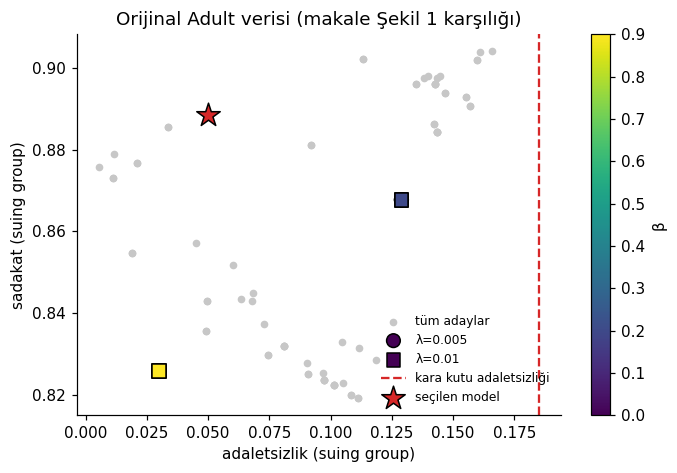

In [5]:
fig = plot_fig1(runs_o[0]["ctx"], "Orijinal Adult verisi (makale Şekil 1 karşılığı)")
plt.show()

**Denetim (makale Şekil 3).** Makalede FairML ile özellik önemi sıralaması yapılır ve aklanmış modelde hassas özelliğin sıralamada çok aşağı düştüğü gösterilir. Ben kara kutu için permütasyon önemini, surrogate'lar için ağaç önemini kullanıyorum (1 = en önemli).

In [6]:
print("Toplam özellik sayısı:", runs_o[0]["ctx"]["X"].shape[1])
audit(runs_o[0]["ctx"])

Toplam özellik sayısı: 104


,kara kutu,dürüst surrogate,aklanmış surrogate
sex_Female,22,12,16
sex_Male,21,18,18


## 3. Kendi verimle: Kaggle German Credit

Kendi veri setim olarak **Kaggle German Credit** verisini seçtim: 1000 kredi başvurusu, 9 sütun (`Age`, `Sex`, `Job`, `Housing`, `Saving accounts`, `Checking account`, `Credit amount`, `Duration`, `Purpose`). Hedef `Risk` (good = 1), hassas özellik `Sex` (erkek = 1). Makalenin iki verisinden (Adult, ProPublica) küçük ve farklı: bu yüzden aklamanın küçük bir veride de çalışıp çalışmadığını, ve test kümesinde de geçerli kalıp kalmadığını sınıyor.

Kodlama: `Housing`, `Saving accounts`, `Checking account`, `Purpose` one-hot. Bölme %40 eğitim / %30 suing group / %30 test (eğitim 400, suing 300, test 300 örnek). Dosya `veri.csv` adıyla klasörde yoksa, defter onu indirir.

In [9]:
german = load_german()
print("German:", german[0].shape, "| good oranı:", german[1].mean().round(3),
      "| erkek oranı:", german[0]["Sex"].mean().round(3))
runs_g = [run_pipeline(german, s, frac_tr=0.4, msl=10, keep=(s == 0)) for s in range(5)]
tab_g = summarize(runs_g)
tab_g[COLS].round(3)

veri.csv bulunamadı. Açılan pencereden veri.csv dosyasını seçin.


Saving veri.csv to veri.csv
German: (1000, 25) | good oranı: 0.7 | erkek oranı: 0.69


,bb_acc_te,bb_unf_su,bb_unf_te,taban_fid,fid_su,unf_su,unf_te,K,kural_saglandi,dürüst_model
seed,,,,,,,,,,
0,0.693,0.067,0.029,0.747,0.920,0.029,0.014,14,True,False
1,0.713,0.081,0.028,0.813,0.907,0.008,0.064,8,True,True
2,0.733,0.083,0.102,0.823,0.900,0.040,0.018,8,True,True
3,0.713,0.155,0.146,0.830,0.900,0.032,0.052,11,True,False
4,0.690,0.052,0.052,0.770,0.900,0.019,0.011,12,True,True


**Tabloyu okumak için.** `taban_fid`, kara kutunun çoğunluk sınıfını **sabit** tahmin eden en basit surrogate'ın sadakatidir. Seçilen modelin sadakati (`fid_su`) bu tabana yakınsa, "aklama" neredeyse bedavadır: kara kutu zaten çoğunlukla aynı sınıfı tahmin ettiği için her şeyi o sınıfa çeviren bir model hem sadık hem "adil" görünür. `dürüst_model = True` ise seçilen model aklama gerektirmeden zaten adil bir dürüst surrogate'tır, yani ortada aklama yoktur.

### 3.1 β ve λ taraması (makale Şekil 1 karşılığı), kendi verimde

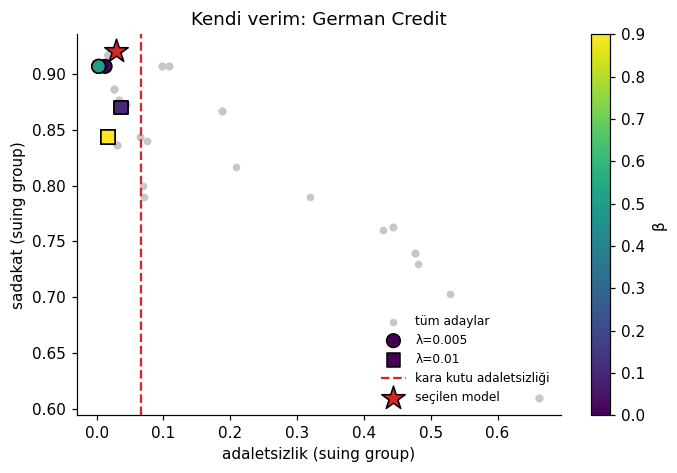

,beta,lam,fid,unfair,K
0,0.0,0.005,0.907,0.013,10
1,0.1,0.005,0.907,0.003,10
2,0.2,0.005,0.907,0.003,10
3,0.5,0.005,0.907,0.003,10
4,0.7,0.005,0.843,0.017,4
5,0.9,0.005,0.843,0.017,4
6,0.0,0.010,0.870,0.037,6
7,0.1,0.010,0.870,0.037,6
8,0.2,0.010,0.843,0.017,4
9,0.5,0.010,0.843,0.017,4


In [10]:
ctx_g = runs_g[0]["ctx"]
fig = plot_fig1(ctx_g, "Kendi verim: German Credit")
plt.show()
ctx_g["grid"].drop(columns="idx").round(3)

### 3.2 Denetim: hassas özellik nerede?

In [11]:
print("Toplam özellik sayısı:", ctx_g["X"].shape[1])
audit(ctx_g)

Toplam özellik sayısı: 25


,kara kutu,dürüst surrogate,aklanmış surrogate
Sex,9,9,11


### 3.3 Canlı demo: Tek bir kadın müşterinin açıklaması

Test kümesinde kara kutunun *bad* dediği ilk kadın müşteriyi alıyorum. Aynı müşteri için **dürüst** surrogate'ın ve **aklanmış** surrogate'ın izlediği kural yoluna bakıyorum.

In [12]:
Xte, bb_te, s_te = ctx_g["X_te"], ctx_g["bb_te"], ctx_g["s_te"]
cand = np.where((s_te == 0) & (bb_te == 0))[0]
i = int(cand[0]) if len(cand) else int(np.where(s_te == 0)[0][0])
x = Xte.iloc[i]
pool = ctx_g["pool"]
hon = pool[(pool.lw == 0) & pool.use_sens & (pool.depth == 4)].iloc[0]
fw = pool.loc[ctx_g["best_i"]]
ad_ = ["bad", "good"]
print("Müşteri:", {k: x[k] for k in ["Age", "Credit amount", "Duration", "Sex"]})
print("Kara kutu kararı:", ad_[int(bb_te[i])])
for ad, m in [("DÜRÜST surrogate", hon), ("AKLANMIŞ surrogate", fw)]:
    p = int(m.model.predict(x[m.feats].values.reshape(1, -1))[0])
    print(f"\n{ad} (derinlik {m.depth}, {m.K} yaprak, hassas sütun {'açık' if m.use_sens else 'kapalı'}): karar = {ad_[p]}")
    for line in rule_path(m.model, m.feats, x):
        print("   ", line)

Müşteri: {'Age': np.float64(24.0), 'Credit amount': np.float64(1275.0), 'Duration': np.float64(15.0), 'Sex': np.float64(0.0)}
Kara kutu kararı: bad

DÜRÜST surrogate (derinlik 4, 10 yaprak, hassas sütun açık): karar = good
    Checking account_little > 0.50   (müşterinin değeri: 1.00)
    Duration <= 28.50   (müşterinin değeri: 15.00)
    Credit amount > 1239.50   (müşterinin değeri: 1275.00)
    Duration <= 17.00   (müşterinin değeri: 15.00)

AKLANMIŞ surrogate (derinlik 6, 14 yaprak, hassas sütun kapalı): karar = bad
    Checking account_little > 0.50   (müşterinin değeri: 1.00)
    Duration <= 28.50   (müşterinin değeri: 15.00)
    Credit amount <= 1316.50   (müşterinin değeri: 1275.00)
    Age <= 36.50   (müşterinin değeri: 24.00)


## 4. Aklama ne zaman işe yarar? Duyarlılık analizi

**4.1 Suing group boyutu (makale Tablo 1, test sütunu).** Aklama suing group'ta yapılıyor. Küçük bir suing group'ta bulunan "adil" model, test kümesinde de adil kalıyor mu? Suing group'u rastgele alt örneklerle küçültüp her seferinde aklamayı yeniden yapıyor ve **test** adaletsizliğine bakıyorum (her boyut için 5 rastgele alt örnek).

,bb_unf_su,unf_su,fid_su,unf_te,fid_te,test − suing adaletsizliği
n,,,,,,
75,0.131,0.075,0.837,0.022,0.789,-0.053
150,0.092,0.016,0.855,0.019,0.818,0.003
225,0.051,0.019,0.888,0.024,0.839,0.005
300,0.067,0.029,0.920,0.014,0.883,-0.015


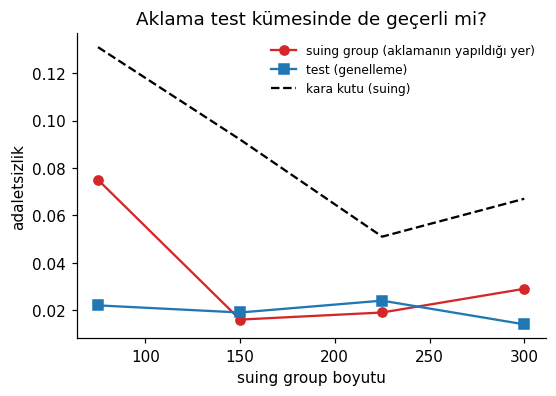

In [13]:
n_full = len(ctx_g["X_su"])
sizes = sorted({max(40, int(n_full * f)) for f in (0.25, 0.5, 0.75, 1.0)})
sz = pd.DataFrame([fairwash_subset(ctx_g, n, seed=100 + r) for n in sizes for r in range(5)])
sz_ozet = sz.groupby("n").mean().round(3)
sz_ozet["test − suing adaletsizliği"] = (sz_ozet.unf_te - sz_ozet.unf_su).round(3)
display(sz_ozet)

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(sz_ozet.index, sz_ozet.unf_su, "o-", color=COL_FW, label="suing group (aklamanın yapıldığı yer)")
ax.plot(sz_ozet.index, sz_ozet.unf_te, "s-", color=COL_HON, label="test (genelleme)")
ax.plot(sz_ozet.index, sz_ozet.bb_unf_su, "k--", label="kara kutu (suing)")
ax.set(xlabel="suing group boyutu", ylabel="adaletsizlik", title="Aklama test kümesinde de geçerli mi?")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**4.2 Model karmaşıklığı.** Aynı kuralla (en az 2 kat daha adil, en sadakatli), ama aday havuzunu ağaç derinliğiyle sınırlayarak: aklamanın sadakat bedeli model karmaşıklığına nasıl bağlı?

In [14]:
rows = []
for d in sorted(ctx_g["pool"].depth.unique()):
    sub = ctx_g["pool"][ctx_g["pool"].depth == d]
    ok_ = sub[sub.unfair <= ctx_g["bb_unf_su"] / 2]
    if len(ok_):
        b = ok_.loc[ok_.fid.idxmax()]
        rows.append(dict(derinlik=d, yaprak=b.K, sadakat=b.fid, adaletsizlik=b.unfair))
    else:
        rows.append(dict(derinlik=d, yaprak=np.nan, sadakat=np.nan, adaletsizlik=np.nan))
karm = pd.DataFrame(rows).set_index("derinlik")
karm.round(3)

,yaprak,sadakat,adaletsizlik
derinlik,,,
2,4,0.843,0.017
3,6,0.843,0.017
4,10,0.907,0.013
5,12,0.917,0.017
6,14,0.920,0.029
8,14,0.920,0.029


## 5. Uzantı: FRAUD-Detect bu aklamayı yakalar mı?

Fairwashing makalesinin (2019) ardından aynı gruba yakın bir ekip tespit üzerine çalıştı (Shamsabadi ve ark., NeurIPS 2022). **Test:** kendi verimde seçtiğim aklanmış modeli, makalenin FRAUD-Detect algoritmasıyla taramak. Beklenen: aklama arttıkça $C_{KL}$ artar. Eşik τ'yu, dürüst surrogate'ların bootstrap dağılımının 95. yüzdeliği olarak kendim kalibre ettim (makalenin Ek G değerleri değil).

**5.1 Aday havuzunda ε ve C_KL.** ε = kara kutunun adaletsizliği − surrogate'ın adaletsizliği ("ne kadar aklandı").

τ = 0.0521 | seçilen modelin C_KL = 0.0474 | Spearman(ε, C_KL) = -0.828


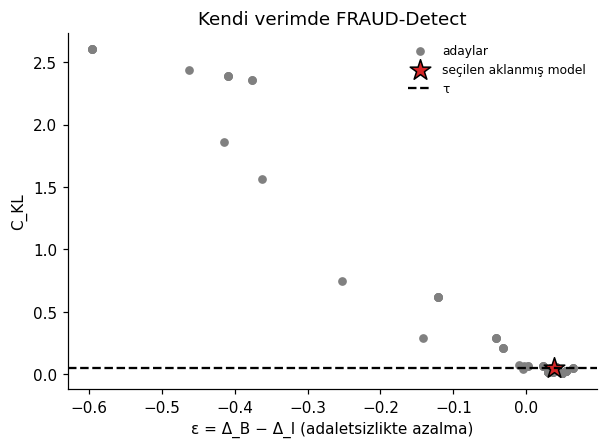

In [15]:
pool = ctx_g["pool"].copy()
pool["eps"] = ctx_g["bb_unf_su"] - pool.unfair
rho = pool[["eps", "ckl"]].corr(method="spearman").iloc[0, 1]
print(f"τ = {ctx_g['tau']:.4f} | seçilen modelin C_KL = {pool.ckl[ctx_g['best_i']]:.4f} | Spearman(ε, C_KL) = {rho:.3f}")

fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.scatter(pool.eps, pool.ckl, s=22, color="gray", label="adaylar")
ax.scatter(pool.eps[ctx_g["best_i"]], pool.ckl[ctx_g["best_i"]], s=200, color=COL_FW, marker="*", edgecolor="k", label="seçilen aklanmış model")
ax.axhline(ctx_g["tau"], ls="--", color="k", label="τ")
ax.set(xlabel="ε = Δ_B − Δ_I (adaletsizlikte azalma)", ylabel="C_KL", title="Kendi verimde FRAUD-Detect")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**5.2 Doğrulama: tespitçi kontrollü bir aklamayı yakalıyor mu?** Ağaç havuzunda eğilim zayıf çıkarsa, bunun tespitçideki bir hatadan mı yoksa aday havuzundan mı kaynaklandığını ayırmak gerekir. Bunun için kara kutunun kararlarını, adaletsizliği besleyen hücrelerde olasılık $q$ ile **doğrudan çeviriyorum** ("ideal" aklama). Karşılaştırma: gruptan bağımsız rastgele gürültü.

In [16]:
QS = [0, 0.05, 0.10, 0.15, 0.20, 0.25]
ctx_o = runs_o[0]["ctx"]
ctrl_o = controlled(ctx_o, QS)
ctrl_g = controlled(ctx_g, QS)
print(f"ADULT (suing group {len(ctx_o['X_su'])} örnek, τ = {ctx_o['tau']:.3f})")
print(ctrl_o.round(4).to_string(index=False))
print(f"\nGERMAN (suing group {len(ctx_g['X_su'])} örnek, τ = {ctx_g['tau']:.3f})")
print(ctrl_g.round(4).to_string(index=False))

ADULT (suing group 11305 örnek, τ = 0.021)
   q  sadakat  eps_aklama  CKL_aklama  eps_gürültü  CKL_gürültü
0.00   1.0000      0.0000      0.0007       0.0000       0.0007
0.05   0.9775      0.0539      0.1368       0.0048       0.0001
0.10   0.9501      0.1214      0.3588       0.0164       0.0003
0.15   0.9288      0.1738      0.5461       0.0199       0.0002
0.20   0.9034      0.1360      0.7687       0.0223       0.0013
0.25   0.8750      0.0613      1.0760       0.0261       0.0002

GERMAN (suing group 300 örnek, τ = 0.052)
   q  sadakat  eps_aklama  CKL_aklama  eps_gürültü  CKL_gürültü
0.00   1.0000      0.0000      0.0025       0.0000       0.0025
0.05   0.9767      0.0460      0.0672       0.0238       0.0246
0.10   0.9033     -0.0175      0.1361       0.0333       0.0272
0.15   0.9133     -0.0032      0.1256       0.0286       0.0445
0.20   0.8600     -0.1048      0.3771       0.0540       0.0150
0.25   0.8300     -0.1476      0.4131       0.0079       0.0124


**5.3 Beş bölmede tespit oranı.**

In [17]:
tespit = pd.DataFrame({
    "Adult: tespit edildi": tab_o.detected,
    "Adult: C_KL": tab_o.ckl.round(3), "Adult: τ": tab_o.tau.round(3),
    "German: tespit edildi": tab_g.detected,
    "German: C_KL": tab_g.ckl.round(3), "German: τ": tab_g.tau.round(3),
})
tespit

,Adult: tespit edildi,Adult: C_KL,Adult: τ,German: tespit edildi,German: C_KL,German: τ
seed,,,,,,
0,True,0.120,0.021,False,0.047,0.052
1,True,0.117,0.025,False,0.017,0.052
2,True,0.104,0.023,False,0.009,0.044
3,True,0.121,0.028,False,0.020,0.213
4,True,0.065,0.027,False,0.053,0.231


## 6. Sonuç ve tartışma

Aşağıdaki hücre, yukarıdaki hücrelerin çıktılarından sonuç metnini **otomatik yazar**. Böylece defteri farklı tohumlarla ya da farklı veriyle çalıştırdığınızda metin de güncellenir.

In [19]:
def pm(a):
    return f"{a.mean():.3f} ± {a.std():.3f}"

ok_o, ok_g = int(tab_o.kural_saglandi.sum()), int(tab_g.kural_saglandi.sum())
det_o, det_g = int(tab_o.detected.sum()), int(tab_g.detected.sum())
gen_o = (tab_o.unf_te - tab_o.unf_su).mean()
gen_g = (tab_g.unf_te - tab_g.unf_su).mean()
q20 = ctrl_o[ctrl_o.q == 0.20].iloc[0]
q20g = ctrl_g[ctrl_g.q == 0.20].iloc[0]
kontrol_ok = bool(q20.CKL_aklama > ctx_o["tau"] and q20.CKL_gürültü < ctx_o["tau"])
kontrol_ok_g = bool(q20g.CKL_aklama > ctx_g["tau"] and q20g.CKL_gürültü < ctx_g["tau"])
gercek_aklama_o = int((~tab_o.dürüst_model & tab_o.kural_saglandi).sum())
gercek_aklama_g = int((~tab_g.dürüst_model & tab_g.kural_saglandi).sum())
taban_yakin_g = bool((tab_g.fid_su - tab_g.taban_fid).mean() < 0.03)
taban_yakin_o = bool((tab_o.fid_su - tab_o.taban_fid).mean() < 0.03)
son = sz_ozet.iloc[0]
full = sz_ozet.iloc[-1]

metin = f"""
**1. Orijinal bulgu (Adult).** 5 bölmede kara kutunun adaletsizliği suing group'ta {pm(tab_o.bb_unf_su)}, testte {pm(tab_o.bb_unf_te)} (makale: 0,13 ve 0,18). Seçilen aklanmış modelde sadakat {pm(tab_o.fid_su)} (makale: 0,908) ve adaletsizlik {pm(tab_o.unf_su)} (makale: 0,058). "En az 2 kat daha adil" kuralı {ok_o}/5 bölmede sağlandı. Makalenin ana mesajı, yani **sadakati yüksek tutarken adaletsizliği ciddi biçimde düşürmek**, {"yeniden üretildi" if (ok_o >= 3 and tab_o.fid_su.mean() > 0.8) else "bu kurulumda tam yeniden üretilemedi (aday havuzumuz makalenin kural listesi numaralandırmasından farklı)"}.

**2. Aklama kendi verime de taşınıyor mu (German Credit).** Kara kutunun adaletsizliği suing group'ta {pm(tab_g.bb_unf_su)}. Seçilen modelde sadakat {pm(tab_g.fid_su)}, adaletsizlik {pm(tab_g.unf_su)}; kural {ok_g}/5 bölmede sağlandı. Küçük bir veride (300 örneklik suing group) bile adaletsizlik {"belirgin biçimde düşürülebildi" if (tab_g.unf_su.mean() <= tab_g.bb_unf_su.mean() / 2) else "yeterince düşürülemedi"}. **Önemli uyarı:** çoğunluk sınıfını sabit tahmin eden surrogate'ın sadakati {pm(tab_g.taban_fid)}; seçilen modelin sadakati buna {"çok yakın, yani bu veride aklama neredeyse bedavaya geliyor (kara kutu çoğunlukla aynı sınıfı tahmin ediyor)" if taban_yakin_g else "göre belirgin biçimde yüksek"}. Seçilen modelin gerçekten aklanmış (dürüst olmayan) olduğu bölme sayısı: {gercek_aklama_g}/5 (Adult'ta {gercek_aklama_o}/5; Adult'ta tabana yakınlık: {"evet" if taban_yakin_o else "hayır"}).

**3. Genelleme.** Aklama suing group'ta yapıldığı için test kümesindeki adaletsizlik suing group'takinden ortalama {gen_o:+.3f} (Adult) ve {gen_g:+.3f} (German) farklı çıktı. Suing group'u {int(son.name)} örneğe düşürdüğümde test adaletsizliği {son.unf_te:.3f} (suing'de {son.unf_su:.3f}); tam boyutta ({int(full.name)}) {full.unf_te:.3f} ({full.unf_su:.3f}). {"Küçük suing group'larda aklama test kümesine daha kötü genelleniyor." if son["test − suing adaletsizliği"] > full["test − suing adaletsizliği"] else "Bu veride küçük suing group'ta genelleme farkı büyümedi."}

**4. Tespit (uzantı).** FRAUD-Detect, seçilen aklanmış modeli Adult'ta {det_o}/5, German'da {det_g}/5 bölmede yakaladı. German'da aday havuzunda ε ile C_KL arasındaki Spearman korelasyonu {rho:.2f}. Doğrulama (kontrollü aklama, q = 0,20): Adult'ta C_KL = {q20.CKL_aklama:.2f} (aklama) ve {q20.CKL_gürültü:.3f} (gürültü), τ = {ctx_o['tau']:.2f}; German'da {q20g.CKL_aklama:.2f} ve {q20g.CKL_gürültü:.3f}, τ = {ctx_g['tau']:.2f}. {"Adult'ta tespitçi doğru çalışıyor: ideal aklamayı yakalıyor, gürültüyü yakalamıyor." if kontrol_ok else "Adult'ta kontrollü deneyde tespitçi beklenen ayrımı yapamadı; τ kalibrasyonuna bakmak gerekir."} {"German'da da doğru çalışıyor." if kontrol_ok_g else "German'da (300 örneklik suing group, küçük alt gruplar) tespitçi kontrollü deneyde de güvenilir ayrım yapamadı: küçük veride C_KL ve τ oynak."} {"Ağaç havuzuyla yapılan aklama ise çoğunlukla tespit edilemedi. Bu, tespitin her aklamayı yakalayamayacağını gösterir (makale de bilgili bir saldırganın tespiti dolanabileceğini söyler)." if (det_o + det_g) <= 4 and kontrol_ok else ""}

**Sınırlar ve dürüstlük notları**
* LaundryML'in CORELS kural listeleri yerine karar ağacı havuzu kullandım. Aday sayısı makaledeki 50 modelli numaralandırmadan farklı, sayılar birebir aynı değil.
* Veri bölme oranları makalede yok, kendim seçtim. Sonuçlar bölmeye duyarlı (5 tohumlu ± std'ye bakın).
* FairML yerine permütasyon önemi kullandım.
* FRAUD-Detect'in eşiği τ'yu makaledeki Ek G'den değil, kendi bootstrap kalibrasyonumdan aldım.
* Yalnızca demografik parite ve ikili hassas özellik ele alındı (makalenin kendi sınırı).

**Savunma için olası sorular**
* *Neden işe yarıyor?* Denetçi yalnızca açıklamayı (surrogate'ı) görüyor. Sadakat yüksekse açıklama doğru kabul ediliyor, ama sadakat, hatanın **nerede** yapıldığını söylemiyor. Hatalar adaletsizliği besleyen hücrelere yığılabilir.
* *Nasıl korunulur?* Genel sadakat yerine **alt grup bazlı** sadakata ve hata yönüne bakmak (FRAUD-Detect'in yaptığı), açıklamayı suing group dışında bir kümede doğrulamak.
* *Bu bir zafiyet mi?* Evet: güvenilir görünen bir açıklama, adaletsizliği gizlemek için kasıtlı olarak üretilebilir.
"""
display(Markdown(metin))


**1. Orijinal bulgu (Adult).** 5 bölmede kara kutunun adaletsizliği suing group'ta 0.189 ± 0.011, testte 0.196 ± 0.010 (makale: 0,13 ve 0,18). Seçilen aklanmış modelde sadakat 0.887 ± 0.005 (makale: 0,908) ve adaletsizlik 0.058 ± 0.016 (makale: 0,058). "En az 2 kat daha adil" kuralı 5/5 bölmede sağlandı. Makalenin ana mesajı, yani **sadakati yüksek tutarken adaletsizliği ciddi biçimde düşürmek**, yeniden üretildi.

**2. Aklama kendi verime de taşınıyor mu (German Credit).** Kara kutunun adaletsizliği suing group'ta 0.088 ± 0.040. Seçilen modelde sadakat 0.905 ± 0.009, adaletsizlik 0.025 ± 0.012; kural 5/5 bölmede sağlandı. Küçük bir veride (300 örneklik suing group) bile adaletsizlik belirgin biçimde düşürülebildi. **Önemli uyarı:** çoğunluk sınıfını sabit tahmin eden surrogate'ın sadakati 0.797 ± 0.036; seçilen modelin sadakati buna göre belirgin biçimde yüksek. Seçilen modelin gerçekten aklanmış (dürüst olmayan) olduğu bölme sayısı: 2/5 (Adult'ta 5/5; Adult'ta tabana yakınlık: hayır).

**3. Genelleme.** Aklama suing group'ta yapıldığı için test kümesindeki adaletsizlik suing group'takinden ortalama +0.004 (Adult) ve +0.006 (German) farklı çıktı. Suing group'u 75 örneğe düşürdüğümde test adaletsizliği 0.022 (suing'de 0.075); tam boyutta (300) 0.014 (0.029). Bu veride küçük suing group'ta genelleme farkı büyümedi.

**4. Tespit (uzantı).** FRAUD-Detect, seçilen aklanmış modeli Adult'ta 5/5, German'da 0/5 bölmede yakaladı. German'da aday havuzunda ε ile C_KL arasındaki Spearman korelasyonu -0.83. Doğrulama (kontrollü aklama, q = 0,20): Adult'ta C_KL = 0.77 (aklama) ve 0.001 (gürültü), τ = 0.02; German'da 0.38 ve 0.015, τ = 0.05. Adult'ta tespitçi doğru çalışıyor: ideal aklamayı yakalıyor, gürültüyü yakalamıyor. German'da da doğru çalışıyor. 

**Sınırlar ve dürüstlük notları**
* LaundryML'in CORELS kural listeleri yerine karar ağacı havuzu kullandım. Aday sayısı makaledeki 50 modelli numaralandırmadan farklı, sayılar birebir aynı değil.
* Veri bölme oranları makalede yok, kendim seçtim. Sonuçlar bölmeye duyarlı (5 tohumlu ± std'ye bakın).
* FairML yerine permütasyon önemi kullandım.
* FRAUD-Detect'in eşiği τ'yu makaledeki Ek G'den değil, kendi bootstrap kalibrasyonumdan aldım.
* Yalnızca demografik parite ve ikili hassas özellik ele alındı (makalenin kendi sınırı).

**Savunma için olası sorular**
* *Neden işe yarıyor?* Denetçi yalnızca açıklamayı (surrogate'ı) görüyor. Sadakat yüksekse açıklama doğru kabul ediliyor, ama sadakat, hatanın **nerede** yapıldığını söylemiyor. Hatalar adaletsizliği besleyen hücrelere yığılabilir.
* *Nasıl korunulur?* Genel sadakat yerine **alt grup bazlı** sadakata ve hata yönüne bakmak (FRAUD-Detect'in yaptığı), açıklamayı suing group dışında bir kümede doğrulamak.
* *Bu bir zafiyet mi?* Evet: güvenilir görünen bir açıklama, adaletsizliği gizlemek için kasıtlı olarak üretilebilir.
